# **GPT por dentro: construyendo un modelo de lenguaje desde cero**

En este notebook vamos a construir, pieza a pieza, un **GPT** (*Generative Pre-trained Transformer*) usando solo PyTorch. La idea no es conseguir el mejor modelo posible, sino **entender qué ocurre dentro**: qué forma tienen los tensores, por qué existe cada componente y cómo encaja todo.

### ¿Qué hace un GPT?

Un GPT es, en esencia, una función que recibe una secuencia de tokens y devuelve, **para cada posición, una distribución de probabilidad sobre cuál será el siguiente token**:

$$P(x_{t+1} \mid x_1, x_2, \dots, x_t)$$

Para generar texto basta con repetir: predecir el siguiente token, añadirlo a la secuencia y volver a predecir.

### El recorrido completo

```
 "Once upon a"                                         texto
      │  tokenizador
      ▼
 [7454, 2402, 257]                                     ids de tokens          (B, T)
      │  embedding de token + embedding de posición
      ▼
 x                                                     vectores               (B, T, d_model)
      │  N × Bloque Transformer
      │        ├─ LayerNorm → Atención causal multi-cabeza → + residual
      │        └─ LayerNorm → MLP                          → + residual
      ▼
 LayerNorm final → lm_head (proyección al vocabulario)
      ▼
 logits                                                puntuaciones           (B, T, vocab_size)
      │  softmax
      ▼
 P(siguiente token)
```

Notación que usaremos en todo el notebook:

| Símbolo | Significado |
|---|---|
| `B` | tamaño del *batch* (cuántas secuencias procesamos a la vez) |
| `T` | longitud de la secuencia (número de tokens) |
| `C` o `d_model` | dimensión de los vectores internos del modelo |
| `n_heads`, `head_dim` | número de cabezas de atención y dimensión de cada una (`d_model = n_heads · head_dim`) |
| `V` o `vocab_size` | tamaño del vocabulario |

### Índice
0. Preparación
1. Tokenización: de texto a números
2. Embeddings: de números a vectores
3. Atención causal, paso a paso (una cabeza)
4. Atención multi-cabeza
5. El MLP (*feed-forward*)
6. El bloque Transformer: LayerNorm y conexiones residuales
7. El modelo GPT completo
8. Comprobaciones antes de entrenar
9. Los datos
10. Entrenamiento
11. Generación de texto: temperatura y top-k
12. ¿A qué presta atención el modelo entrenado?
13. Ejercicios propuestos

## **0. Preparación**

Importamos las librerías, fijamos una semilla (para que los resultados sean reproducibles) y elegimos el dispositivo: GPU NVIDIA (`cuda`), GPU de Apple (`mps`) o CPU.

In [2]:
import math
import time
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
import tiktoken
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"Usando dispositivo: {device}")

Usando dispositivo: mps


## **1. Tokenización: de texto a números**

Una red neuronal no entiende de letras: necesita números. El **tokenizador** parte el texto en trozos (*tokens*) y asigna a cada uno un número entero (su *id*).

Usamos el tokenizador de GPT-2 (*Byte-Pair Encoding*, BPE), con **50 257 tokens**. Fíjate en que:
- las palabras frecuentes suelen ser un único token,
- las palabras raras se parten en varios trozos,
- el espacio forma parte del token (`" upon"` es distinto de `"upon"`).

In [3]:
enc = tiktoken.get_encoding("gpt2")

texto = "Once upon a time, a tokenizer split extraordinarily long words."
ids = enc.encode(texto)

print(f"Texto: {texto!r}")
print(f"Ids:   {ids}")
print(f"Número de caracteres: {len(texto)}  →  número de tokens: {len(ids)}\n")

for i in ids:
    print(f"{i:>6}  →  {enc.decode([i])!r}")

print(f"\nTamaño del vocabulario: {enc.n_vocab}")
print(f"Token especial de fin de texto <|endoftext|>: {enc.eot_token}")

Texto: 'Once upon a time, a tokenizer split extraordinarily long words.'
Ids:   [7454, 2402, 257, 640, 11, 257, 11241, 7509, 6626, 31999, 890, 2456, 13]
Número de caracteres: 63  →  número de tokens: 13

  7454  →  'Once'
  2402  →  ' upon'
   257  →  ' a'
   640  →  ' time'
    11  →  ','
   257  →  ' a'
 11241  →  ' token'
  7509  →  'izer'
  6626  →  ' split'
 31999  →  ' extraordinarily'
   890  →  ' long'
  2456  →  ' words'
    13  →  '.'

Tamaño del vocabulario: 50257
Token especial de fin de texto <|endoftext|>: 50256


## **2. Embeddings: de números a vectores**

Un id (por ejemplo `7454`) es solo una etiqueta: el número en sí no significa nada. El primer paso del modelo es convertir cada id en un **vector** de dimensión `d_model` mediante una tabla aprendible, `nn.Embedding(vocab_size, d_model)`. Es literalmente una matriz donde la fila `i` es el vector del token `i`.

**Problema:** la atención (que veremos enseguida) trata la secuencia como un *conjunto*: no sabe qué token va primero. Por eso sumamos un segundo embedding, el **embedding posicional**, que codifica la posición (0, 1, 2, ...) de cada token. En GPT-2 también es una tabla aprendible.

$$x_t = \text{TokEmb}[\text{id}_t] + \text{PosEmb}[t]$$

In [4]:
d_model_demo = 8      # dimensión pequeña solo para poder imprimir los vectores
block_size_demo = 16  # longitud máxima de secuencia

tok_emb = nn.Embedding(enc.n_vocab, d_model_demo)
pos_emb = nn.Embedding(block_size_demo, d_model_demo)

idx = torch.tensor([enc.encode("Once upon a time")])   # (B=1, T=4)
B, T = idx.shape
print("idx:", idx, "  shape:", tuple(idx.shape), "→ (B, T)")

t = tok_emb(idx)                    # (B, T, d_model)
p = pos_emb(torch.arange(T))        # (T, d_model)
x = t + p                           # broadcasting: (B, T, d_model) + (T, d_model)

print("embedding de token:     ", tuple(t.shape), "→ (B, T, d_model)")
print("embedding de posición:  ", tuple(p.shape), "→ (T, d_model)")
print("x = token + posición:   ", tuple(x.shape), "→ (B, T, d_model)")
print("\nVector del primer token ('Once' en la posición 0):\n", x[0, 0].detach())

idx: tensor([[7454, 2402,  257,  640]])   shape: (1, 4) → (B, T)
embedding de token:      (1, 4, 8) → (B, T, d_model)
embedding de posición:   (4, 8) → (T, d_model)
x = token + posición:    (1, 4, 8) → (B, T, d_model)

Vector del primer token ('Once' en la posición 0):
 tensor([ 1.9439, -3.0286, -0.3231, -1.3075,  0.9939,  0.5390,  2.4499,  0.4913])


## **3. Atención causal, paso a paso (una cabeza)**

La atención es el corazón del Transformer. Permite que cada token **recoja información de los tokens anteriores** que le resulten relevantes.

Cada token genera tres vectores mediante tres capas lineales:
- **Query (Q)**: *"¿qué estoy buscando?"*
- **Key (K)**: *"¿qué ofrezco?"*
- **Value (V)**: *"si te intereso, esta es la información que te paso"*.

La afinidad entre el token $i$ y el token $j$ es el producto escalar $q_i \cdot k_j$. Tras normalizar con softmax, cada token obtiene una media ponderada de los *values*:

$$\text{Atención}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right) V$$

donde $M$ es la **máscara causal**: vale $-\infty$ en las posiciones futuras, para que un token **no pueda mirar al futuro** (si pudiera, ¡predecir el siguiente token sería trampa!).

Vamos a hacerlo a mano con un ejemplo minúsculo: `T = 5` tokens y vectores de dimensión `C = 8`.

In [6]:
torch.manual_seed(0)
B, T, C = 1, 5, 8
x = torch.randn(B, T, C)          # pretendamos que son los embeddings de 5 tokens

head_dim = C                      # con una sola cabeza, head_dim = C
W_q = nn.Linear(C, head_dim, bias=False)
W_k = nn.Linear(C, head_dim, bias=False)
W_v = nn.Linear(C, head_dim, bias=False)

q, k, v = W_q(x), W_k(x), W_v(x)  # cada uno: (B, T, head_dim)
print("q, k, v:", tuple(q.shape))

# Paso 1: afinidades entre todos los pares de tokens (producto escalar q_i · k_j)
scores = q @ k.transpose(-2, -1)                     # (B, T, T)
# Paso 2: escalado por sqrt(head_dim) (enseguida vemos por qué)
scores = scores / math.sqrt(head_dim)
print("scores:", tuple(scores.shape), "→ fila i = cuánto le interesa cada token j al token i")

q, k, v: (1, 5, 8)
scores: (1, 5, 5) → fila i = cuánto le interesa cada token j al token i


In [7]:
# Paso 3: máscara causal. tril = triangular INFERIOR de unos.
mask = torch.tril(torch.ones(T, T))
print("Máscara causal (1 = se puede mirar, 0 = futuro prohibido):\n", mask)

scores_masked = scores.masked_fill(mask == 0, float("-inf"))
print("\nScores tras la máscara (fila 0):", scores_masked[0, 0].detach())

Máscara causal (1 = se puede mirar, 0 = futuro prohibido):
 tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])

Scores tras la máscara (fila 0): tensor([0.2491,   -inf,   -inf,   -inf,   -inf])


Pesos de atención:
 [[1.   0.   0.   0.   0.  ]
 [0.45 0.55 0.   0.   0.  ]
 [0.32 0.34 0.34 0.   0.  ]
 [0.22 0.31 0.21 0.26 0.  ]
 [0.14 0.16 0.17 0.16 0.36]]

Suma de cada fila: tensor([1., 1., 1., 1., 1.])

Salida de la atención: (1, 5, 8)


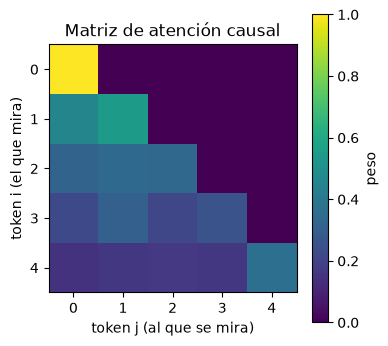

In [8]:
# Paso 4: softmax por filas → cada fila es una distribución de probabilidad
att = F.softmax(scores_masked, dim=-1)               # (B, T, T)
print("Pesos de atención:\n", att[0].detach().numpy().round(2))
print("\nSuma de cada fila:", att[0].sum(dim=-1).detach())

# Paso 5: media ponderada de los values
out = att @ v                                        # (B, T, T) @ (B, T, head_dim) → (B, T, head_dim)
print("\nSalida de la atención:", tuple(out.shape))

plt.figure(figsize=(4, 4))
plt.imshow(att[0].detach(), cmap="viridis")
plt.colorbar(label="peso")
plt.xlabel("token j (al que se mira)")
plt.ylabel("token i (el que mira)")
plt.title("Matriz de atención causal")
plt.show()

Observa:
- El **triángulo superior es cero**: el token $i$ nunca mira a tokens $j > i$.
- El **primer token** solo puede mirarse a sí mismo (peso 1.0).
- Cada fila **suma 1**: la salida es una media ponderada de los *values*.

> **Consecuencia importante:** gracias a la máscara, con **una sola pasada** el modelo hace `T` predicciones a la vez (la posición 0 predice el token 1, la 1 predice el 2, ...). Esto hace que el entrenamiento sea muy eficiente.

### ¿Por qué dividimos por $\sqrt{d_k}$?

Si los elementos de `q` y `k` tienen varianza 1, su producto escalar (una suma de `d_k` términos) tiene **varianza `d_k`**. Con valores grandes, el softmax se satura (casi todo el peso va a un único token) y los gradientes se vuelven diminutos. Dividir por $\sqrt{d_k}$ devuelve la varianza a 1.

In [9]:
for d in [8, 64, 512]:
    q_ = torch.randn(10_000, d)
    k_ = torch.randn(10_000, d)
    dot = (q_ * k_).sum(dim=-1)
    print(f"d_k={d:>4}:  var(q·k) = {dot.var():7.1f}   var(q·k/√d_k) = {(dot / math.sqrt(d)).var():.2f}")

logits_demo = torch.tensor([1.0, 2.0, 3.0])
print("\nsoftmax de valores moderados:", F.softmax(logits_demo, dim=-1).numpy().round(3))
print("softmax de valores ×10:      ", F.softmax(logits_demo * 10, dim=-1).numpy().round(3), "← saturado")

d_k=   8:  var(q·k) =     7.8   var(q·k/√d_k) = 0.97
d_k=  64:  var(q·k) =    65.0   var(q·k/√d_k) = 1.02
d_k= 512:  var(q·k) =   518.4   var(q·k/√d_k) = 1.01

softmax de valores moderados: [0.09  0.245 0.665]
softmax de valores ×10:       [0. 0. 1.] ← saturado


## **4. Atención multi-cabeza**

Una sola cabeza solo puede aprender **un tipo de relación** a la vez. Con varias cabezas, cada una puede especializarse (una en el token anterior, otra en el sujeto de la frase, etc.).

El truco de implementación: en lugar de crear `n_heads` capas separadas, usamos capas lineales de `d_model → d_model` y **partimos el resultado** en `n_heads` trozos de tamaño `head_dim`:

```
(B, T, d_model) ──view──► (B, T, n_heads, head_dim) ──transpose──► (B, n_heads, T, head_dim)
```

Así PyTorch calcula todas las cabezas en paralelo, como si `n_heads` fuera otra dimensión de batch. Al final, deshacemos el cambio (concatenamos las cabezas) y aplicamos una proyección lineal de salida.

In [10]:
class CausalSelfAttention(nn.Module):
    # Atención multi-cabeza con máscara causal.

    def __init__(self, d_model, n_heads, block_size, dropout):
        super().__init__()
        assert d_model % n_heads == 0, "d_model debe ser divisible entre n_heads"
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        # Proyecciones para queries, keys y values (todas las cabezas juntas)
        self.query = nn.Linear(d_model, d_model)
        self.key = nn.Linear(d_model, d_model)
        self.value = nn.Linear(d_model, d_model)
        # Proyección de salida, tras concatenar las cabezas
        self.proj = nn.Linear(d_model, d_model)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # Máscara causal triangular INFERIOR. register_buffer: forma parte del
        # módulo (se mueve a la GPU con .to(device)) pero NO es un parámetro entrenable.
        mask = torch.tril(torch.ones(block_size, block_size))
        self.register_buffer("mask", mask.view(1, 1, block_size, block_size))

        # Aquí guardaremos los pesos de atención para poder visualizarlos (sección 12)
        self.last_att = None

    def forward(self, x):
        B, T, C = x.shape                                   # (B, T, d_model)

        q = self.query(x)                                   # (B, T, d_model)
        k = self.key(x)
        v = self.value(x)

        # Separamos las cabezas: (B, T, d_model) → (B, n_heads, T, head_dim)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        # Afinidades escaladas: (B, nh, T, hd) @ (B, nh, hd, T) → (B, nh, T, T)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # Máscara causal (recortada a la longitud actual T)
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        self.last_att = att.detach()
        att = self.attn_dropout(att)

        # Media ponderada de los values: (B, nh, T, T) @ (B, nh, T, hd) → (B, nh, T, hd)
        y = att @ v

        # Concatenamos las cabezas: (B, nh, T, hd) → (B, T, nh, hd) → (B, T, d_model)
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        return self.resid_dropout(self.proj(y))             # (B, T, d_model)

Comprobemos dos cosas:
1. La salida tiene **la misma forma que la entrada**, `(B, T, d_model)`. Esto es lo que permite apilar bloques.
2. Nuestra implementación da **el mismo resultado** que la función optimizada de PyTorch, `F.scaled_dot_product_attention` (que en la práctica se usa por velocidad; aquí la escribimos a mano para entenderla).

In [11]:
torch.manual_seed(0)
attn = CausalSelfAttention(d_model=32, n_heads=4, block_size=16, dropout=0.0)
x = torch.randn(2, 10, 32)                # (B=2, T=10, d_model=32)
y = attn(x)
print("entrada:", tuple(x.shape), " salida:", tuple(y.shape))

# Misma cuenta con la función de PyTorch
B, T, C = x.shape
def heads(t):
    return t.view(B, T, 4, 8).transpose(1, 2)

q, k, v = heads(attn.query(x)), heads(attn.key(x)), heads(attn.value(x))
y_ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)
y_ref = attn.proj(y_ref.transpose(1, 2).contiguous().view(B, T, C))
print("¿Coincide con F.scaled_dot_product_attention?", torch.allclose(y, y_ref, atol=1e-5))

entrada: (2, 10, 32)  salida: (2, 10, 32)
¿Coincide con F.scaled_dot_product_attention? True


## **5. El MLP (*feed-forward*)**

La atención **mezcla información entre tokens**. El MLP, en cambio, procesa **cada token por separado** (las mismas capas se aplican a cada posición): es donde el modelo "piensa" sobre la información recogida.

Es una red de dos capas que expande la dimensión (habitualmente ×4), aplica una no linealidad (GELU, una versión suave de ReLU) y vuelve a `d_model`:

```
(B, T, d_model) → Linear → (B, T, d_ff) → GELU → Linear → (B, T, d_model)
```

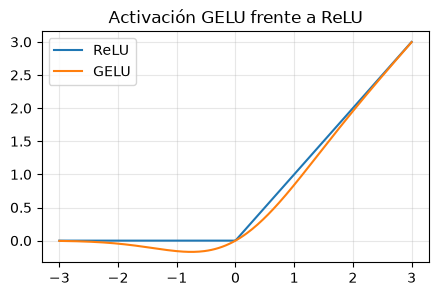

In [12]:
class MLP(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.fc = nn.Linear(d_model, d_ff)      # expansión
        self.act = nn.GELU()
        self.proj = nn.Linear(d_ff, d_model)    # contracción
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.proj(self.act(self.fc(x))))

xs = torch.linspace(-3, 3, 200)
plt.figure(figsize=(5, 3))
plt.plot(xs, F.relu(xs), label="ReLU")
plt.plot(xs, F.gelu(xs), label="GELU")
plt.legend(); plt.grid(alpha=0.3); plt.title("Activación GELU frente a ReLU")
plt.show()

## **6. El bloque Transformer: LayerNorm y conexiones residuales**

Un bloque combina atención y MLP con dos ingredientes que hacen posible entrenar redes profundas:

**Conexiones residuales** (`x = x + f(x)`): cada subcapa no sustituye a `x`, sino que **le suma una corrección**. Hay un "camino directo" (el *residual stream*) por el que la información y los gradientes fluyen sin obstáculos de la entrada a la salida.

**LayerNorm**: normaliza cada vector de token (media 0, varianza 1, más una escala y un desplazamiento aprendibles), lo que mantiene los valores en un rango estable.

Usamos la variante **pre-norm** (la de GPT-2): la normalización se aplica *antes* de cada subcapa, dentro de la rama, sin tocar el camino residual:

```
x ──┬──────────────────────────────(+)──┬─────────────────────(+)──► salida
    └─► LayerNorm ─► Atención ──────┘   └─► LayerNorm ─► MLP ──┘
```

In [13]:
class Block(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, block_size, dropout):
        super().__init__()
        self.ln_1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, block_size, dropout)
        self.ln_2 = nn.LayerNorm(d_model)
        self.mlp = MLP(d_model, d_ff, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))   # los tokens se comunican entre sí
        x = x + self.mlp(self.ln_2(x))    # cada token se procesa individualmente
        return x

ln = nn.LayerNorm(8)
v = torch.randn(1, 3, 8) * 5 + 3
print("Antes de LayerNorm  → media por token:", v.mean(-1).detach().numpy().round(2), " desv.:", v.std(-1).detach().numpy().round(2))
v_n = ln(v)
print("Después de LayerNorm → media por token:", v_n.mean(-1).detach().numpy().round(2), " desv.:", v_n.std(-1, unbiased=False).detach().numpy().round(2))

Antes de LayerNorm  → media por token: [[2.84 0.72 4.52]]  desv.: [[3.66 2.74 5.79]]
Después de LayerNorm → media por token: [[ 0. -0. -0.]]  desv.: [[1. 1. 1.]]


## **7. El modelo GPT completo**

Ya tenemos todas las piezas. El modelo:
1. Convierte ids en vectores (embedding de token + embedding de posición).
2. Los pasa por `n_layers` bloques.
3. Aplica una LayerNorm final.
4. Proyecta cada vector al vocabulario con `lm_head` (`d_model → vocab_size`): obtiene un **logit** (una puntuación) por cada posible siguiente token.

**La función de pérdida** es la entropía cruzada entre los logits y el token que realmente venía después. Como cada posición predice su siguiente token, en una secuencia de `T` tokens hay `T` predicciones que se evalúan a la vez.

Dos detalles de GPT-2 que incluimos:
- **Weight tying**: `lm_head` comparte la matriz de pesos con el embedding de tokens. Tiene sentido (convertir token→vector y vector→token son operaciones "inversas") y ahorra muchísimos parámetros.
- **Inicialización**: pesos normales con `std = 0.02`. Las proyecciones que suman al camino residual se escalan además por $1/\sqrt{2 \cdot n_{layers}}$, para que la varianza no crezca al apilar bloques.

In [14]:
@dataclass
class GPTConfig:
    vocab_size: int = 50257   # tamaño del vocabulario (tokenizador de GPT-2)
    block_size: int = 128     # longitud máxima de contexto (tokens)
    n_layers: int = 4         # número de bloques Transformer
    n_heads: int = 4          # cabezas de atención por bloque
    d_model: int = 256        # dimensión de los vectores internos
    d_ff: int = 1024          # dimensión interna del MLP (normalmente 4·d_model)
    dropout: float = 0.1      # probabilidad de dropout


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config

        self.tok_emb = nn.Embedding(config.vocab_size, config.d_model)
        self.pos_emb = nn.Embedding(config.block_size, config.d_model)
        self.drop = nn.Dropout(config.dropout)
        self.blocks = nn.ModuleList([
            Block(config.d_model, config.n_heads, config.d_ff, config.block_size, config.dropout)
            for _ in range(config.n_layers)
        ])
        self.ln_f = nn.LayerNorm(config.d_model)
        self.lm_head = nn.Linear(config.d_model, config.vocab_size, bias=False)

        # Weight tying: la misma matriz (vocab_size, d_model) para entrada y salida
        self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        # Escalado extra de las proyecciones que suman al camino residual
        for name, p in self.named_parameters():
            if name.endswith("attn.proj.weight") or name.endswith("mlp.proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layers))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.config.block_size, f"Secuencia de {T} tokens > block_size={self.config.block_size}"

        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)          # (B, T, d_model)
        x = self.drop(x)

        for block in self.blocks:
            x = block(x)                                   # (B, T, d_model)

        x = self.ln_f(x)
        logits = self.lm_head(x)                           # (B, T, vocab_size)

        loss = None
        if targets is not None:
            # cross_entropy espera (N, clases) y (N,): aplanamos batch y tiempo
            loss = F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        # Generación autoregresiva: predecimos un token, lo añadimos y repetimos.
        for _ in range(max_new_tokens):
            # El modelo solo admite block_size tokens: nos quedamos con los últimos
            idx_cond = idx[:, -self.config.block_size:]
            logits, _ = self(idx_cond)                     # (B, T, vocab_size)
            logits = logits[:, -1, :] / temperature        # solo nos interesa la última posición

            if top_k is not None:
                # Anulamos todos los logits fuera de los k mayores
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)              # (B, vocab_size)
            idx_next = torch.multinomial(probs, num_samples=1)   # muestreamos (B, 1)
            idx = torch.cat([idx, idx_next], dim=1)
        return idx

Creamos un modelo pequeño (≈ 16 M de parámetros, frente a los 124 M del GPT-2 más pequeño) y vemos dónde están sus parámetros.

In [15]:
config = GPTConfig()
model = GPT(config).to(device)

def contar(m):
    return sum(p.numel() for p in m.parameters())

print(config)
print(f"\nParámetros totales: {contar(model) / 1e6:.2f} M")
print(f"  embedding de tokens (compartido con lm_head): {model.tok_emb.weight.numel() / 1e6:.2f} M")
print(f"  embedding de posición:                        {model.pos_emb.weight.numel() / 1e6:.2f} M")
print(f"  cada bloque Transformer:                      {contar(model.blocks[0]) / 1e6:.2f} M")
print(f"     - atención: {contar(model.blocks[0].attn) / 1e6:.2f} M   - MLP: {contar(model.blocks[0].mlp) / 1e6:.2f} M")

GPTConfig(vocab_size=50257, block_size=128, n_layers=4, n_heads=4, d_model=256, d_ff=1024, dropout=0.1)

Parámetros totales: 16.06 M
  embedding de tokens (compartido con lm_head): 12.87 M
  embedding de posición:                        0.03 M
  cada bloque Transformer:                      0.79 M
     - atención: 0.26 M   - MLP: 0.53 M


> Fíjate en que, en un modelo tan pequeño, **la mayoría de los parámetros están en el embedding de tokens** (50 257 × 256). En modelos grandes ocurre al revés: dominan los bloques.

## **8. Comprobaciones antes de entrenar**

Antes de entrenar conviene comprobar que todo tiene sentido.

**¿Cuánto debería valer la pérdida inicial?** Un modelo recién inicializado no sabe nada, así que debería asignar aproximadamente la misma probabilidad, $1/V$, a todos los tokens. La entropía cruzada sería entonces:

$$-\ln\left(\frac{1}{V}\right) = \ln(50\,257) \approx 10.82$$

Si obtenemos un valor muy distinto, algo está mal (por ejemplo, la inicialización).

In [ ]:
idx = torch.randint(0, config.vocab_size, (4, 32), device=device)      # (B=4, T=32) tokens al azar
targets = torch.randint(0, config.vocab_size, (4, 32), device=device)

logits, loss = model(idx, targets)
print("logits:", tuple(logits.shape), "→ (B, T, vocab_size)")
print(f"Pérdida inicial: {loss.item():.3f}   (esperada ≈ ln({config.vocab_size}) = {math.log(config.vocab_size):.3f})")

Y así "habla" el modelo **antes de entrenar**: tokens al azar.

In [ ]:
def generate_text(model, prompt, max_new_tokens=50, temperature=1.0, top_k=None):
    model.eval()
    idx = torch.tensor([enc.encode(prompt)], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens, temperature=temperature, top_k=top_k)
    return enc.decode(out[0].tolist())

print(generate_text(model, "Once upon a time", max_new_tokens=30))

## **9. Los datos**

Vamos a entrenar con **TinyStories**: cuentos cortos en inglés con un vocabulario sencillo, pensados precisamente para que **modelos pequeños** aprendan a escribir texto coherente. Es mucho más agradecido para un modelo de 16 M de parámetros que un corpus general como OpenWebText.

Para no descargar el dataset entero usamos `streaming=True`: leemos documentos uno a uno hasta reunir `N_TOKENS` tokens. Entre documento y documento insertamos el token `<|endoftext|>`, para que el modelo aprenda dónde acaba una historia.

> **Para cambiar de corpus** basta con cambiar `DATASET_NAME` (por ejemplo, `"Skylion007/openwebtext"`). Con más tokens el modelo aprende más, pero la tokenización tarda más.

In [ ]:
from datasets import load_dataset

DATASET_NAME = "roneneldan/TinyStories"
N_TOKENS = 20_000_000          # cuántos tokens reunir (≈ 100 MB de texto)

stream = load_dataset(DATASET_NAME, split="train", streaming=True)

t0 = time.time()
chunks, total, batch_texts = [], 0, []
for example in stream:
    batch_texts.append(example["text"])
    if len(batch_texts) == 1000:
        # encode_ordinary_batch tokeniza en paralelo y es mucho más rápido que uno a uno
        for toks in enc.encode_ordinary_batch(batch_texts):
            toks.append(enc.eot_token)                 # separador entre documentos
            chunks.append(np.array(toks, dtype=np.uint16))   # uint16 basta: vocab < 65 536
            total += len(toks)
        batch_texts = []
        if total >= N_TOKENS:
            break

data = np.concatenate(chunks)[:N_TOKENS]
print(f"{len(data):,} tokens reunidos en {time.time() - t0:.1f} s")

# 90 % para entrenar, 10 % para validar (texto que el modelo nunca ve al entrenar)
n_train = int(0.9 * len(data))
train_data = torch.from_numpy(data[:n_train].astype(np.int64))
val_data = torch.from_numpy(data[n_train:].astype(np.int64))
print(f"train: {len(train_data):,} tokens   val: {len(val_data):,} tokens")

print("\nUn fragmento del corpus:\n")
print(enc.decode(train_data[:120].tolist()))

### Cómo se construyen los ejemplos de entrenamiento

Tomamos una ventana de `block_size + 1` tokens consecutivos a partir de una posición al azar. La entrada `x` son los primeros `block_size` y el objetivo `y` es **la misma secuencia desplazada una posición**:

```
tokens:   [ Once | upon |  a   | time |  ,   | there ]
x:        [ Once | upon |  a   | time |  ,   ]
y:        [ upon |  a   | time |  ,   | there ]
```

Así, en la posición `t` el modelo ve `x[0..t]` (gracias a la máscara causal) y tiene que predecir `y[t]`.

In [ ]:
def get_batch(split, batch_size, block_size):
    source = train_data if split == "train" else val_data
    starts = torch.randint(0, len(source) - block_size - 1, (batch_size,))
    x = torch.stack([source[s : s + block_size] for s in starts])
    y = torch.stack([source[s + 1 : s + block_size + 1] for s in starts])
    return x.to(device), y.to(device)

x, y = get_batch("train", batch_size=2, block_size=8)
print("x:", tuple(x.shape), "  y:", tuple(y.shape))
print("\nPara la primera secuencia del batch, el modelo aprende que:")
for t in range(8):
    contexto = enc.decode(x[0, : t + 1].tolist())
    objetivo = enc.decode([y[0, t].item()])
    print(f"   {contexto!r:>45}  →  {objetivo!r}")

## **10. Entrenamiento**

El bucle de entrenamiento es el estándar de PyTorch: *forward* → pérdida → *backward* → paso del optimizador. Añadimos tres ingredientes habituales al entrenar Transformers:

- **AdamW con *weight decay***: regularización que penaliza los pesos grandes. No se aplica a sesgos ni a los parámetros de LayerNorm (vectores 1D).
- **Learning rate con *warmup* y decaimiento coseno**: al principio sube poco a poco (los primeros pasos son inestables) y luego baja suavemente hasta el final.
- ***Gradient clipping***: si la norma del gradiente supera 1.0, se reescala para evitar pasos demasiado bruscos.

Cada `EVAL_EVERY` pasos medimos la pérdida en **train** y en **validación**. Si la de validación deja de bajar mientras la de train sigue bajando, el modelo está memorizando (*overfitting*).

> Con GPU, el entrenamiento por defecto tarda unos minutos. Con CPU es mucho más lento: reduce `MAX_STEPS` o el tamaño del modelo.

In [ ]:
# Hiperparámetros de entrenamiento
BATCH_SIZE = 64
MAX_STEPS = 3000
LR_MAX = 1e-3
LR_MIN = LR_MAX / 10
WARMUP_STEPS = 100
WEIGHT_DECAY = 0.1
GRAD_CLIP = 1.0
EVAL_EVERY = 250
EVAL_BATCHES = 50

def get_lr(step):
    if step < WARMUP_STEPS:                                   # 1) warmup lineal
        return LR_MAX * (step + 1) / WARMUP_STEPS
    progreso = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * progreso))   # 2) coseno

plt.figure(figsize=(6, 2.5))
plt.plot([get_lr(s) for s in range(MAX_STEPS)])
plt.xlabel("paso"); plt.ylabel("learning rate"); plt.title("Warmup + decaimiento coseno")
plt.grid(alpha=0.3); plt.show()

In [ ]:
@torch.no_grad()
def estimate_loss(model):
    # Pérdida media sobre varios batches (una sola estimación es muy ruidosa)
    model.eval()                         # desactiva el dropout
    out = {}
    for split in ["train", "val"]:
        losses = [model(*get_batch(split, BATCH_SIZE, config.block_size))[1].item()
                  for _ in range(EVAL_BATCHES)]
        out[split] = sum(losses) / len(losses)
    model.train()                        # vuelve a activar el dropout
    return out

In [ ]:
model = GPT(config).to(device)     # empezamos con un modelo recién inicializado

# Weight decay solo en las matrices (parámetros 2D); no en sesgos ni LayerNorm
decay = [p for p in model.parameters() if p.dim() >= 2]
no_decay = [p for p in model.parameters() if p.dim() < 2]
optimizer = torch.optim.AdamW(
    [{"params": decay, "weight_decay": WEIGHT_DECAY},
     {"params": no_decay, "weight_decay": 0.0}],
    lr=LR_MAX, betas=(0.9, 0.95),
)

history = {"step": [], "train": [], "val": []}
model.train()
t0 = time.time()

for step in range(MAX_STEPS + 1):
    # --- Evaluación periódica ---
    if step % EVAL_EVERY == 0:
        losses = estimate_loss(model)
        history["step"].append(step)
        history["train"].append(losses["train"])
        history["val"].append(losses["val"])
        print(f"paso {step:5d} | train {losses['train']:.3f} | val {losses['val']:.3f} "
              f"| lr {get_lr(step):.2e} | {time.time() - t0:.0f} s")
        if step == MAX_STEPS:
            break

    # --- Un paso de entrenamiento ---
    for g in optimizer.param_groups:              # actualizamos el learning rate
        g["lr"] = get_lr(step)

    x, y = get_batch("train", BATCH_SIZE, config.block_size)
    logits, loss = model(x, y)                    # 1) forward
    optimizer.zero_grad(set_to_none=True)
    loss.backward()                               # 2) backward: calcula gradientes
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)   # 3) clipping
    optimizer.step()                              # 4) actualiza los pesos

In [ ]:
plt.figure(figsize=(6, 3.5))
plt.plot(history["step"], history["train"], "o-", label="train")
plt.plot(history["step"], history["val"], "o-", label="validación")
plt.axhline(math.log(config.vocab_size), color="gray", ls="--", label="azar (ln V)")
plt.xlabel("paso"); plt.ylabel("pérdida (entropía cruzada)")
plt.legend(); plt.grid(alpha=0.3); plt.title("Curvas de aprendizaje")
plt.show()

print(f"Pérdida final en validación: {history['val'][-1]:.3f}")
print(f"Perplejidad = e^pérdida = {math.exp(history['val'][-1]):.1f}")
print("(es como si el modelo dudara, en promedio, entre ese número de tokens igualmente probables)")

## **11. Generación de texto: temperatura y top-k**

Para generar, en cada paso convertimos los logits del último token en probabilidades y **muestreamos** el siguiente token. Dos parámetros controlan cuánto "arriesga" el modelo:

- **Temperatura** ($\tau$): dividimos los logits por $\tau$ antes del softmax.
  - $\tau < 1$ → distribución más **picuda**: texto más predecible y repetitivo.
  - $\tau > 1$ → distribución más **plana**: texto más variado... y más disparatado.
- **Top-k**: solo se puede elegir entre los `k` tokens más probables; el resto recibe probabilidad 0. Evita que, por mala suerte, salga un token absurdo de la "cola" de la distribución.

In [ ]:
logits_demo = torch.tensor([3.0, 2.0, 1.0, 0.5, 0.0, -1.0])
etiquetas = ["dog", "cat", "bird", "fish", "car", "the"]

fig, axes = plt.subplots(1, 4, figsize=(14, 2.8), sharey=True)
for ax, tau in zip(axes, [0.5, 1.0, 2.0, "top-k=2"]):
    if tau == "top-k=2":
        l = logits_demo.clone()
        l[l < torch.topk(l, 2).values[-1]] = float("-inf")
        probs, titulo = F.softmax(l, dim=-1), "τ = 1.0, top-k = 2"
    else:
        probs, titulo = F.softmax(logits_demo / tau, dim=-1), f"τ = {tau}"
    ax.bar(etiquetas, probs)
    ax.set_title(titulo)
axes[0].set_ylabel("probabilidad")
plt.suptitle("Efecto de la temperatura y top-k sobre la distribución del siguiente token", y=1.05)
plt.show()

In [ ]:
prompt = "Once upon a time, there was a little dog named"

for temp in [0.3, 0.8, 1.5]:
    torch.manual_seed(1)
    print(f"===== temperatura = {temp} =====")
    print(generate_text(model, prompt, max_new_tokens=60, temperature=temp, top_k=50))
    print()

Prueba tus propios comienzos de historia:

In [ ]:
print(generate_text(model, "Lily wanted to go to the park, but", max_new_tokens=80, temperature=0.8, top_k=50))

## **12. ¿A qué presta atención el modelo entrenado?**

Cada capa de atención guardó sus pesos en `last_att` durante el último *forward*. Pasamos una frase por el modelo y dibujamos la matriz de atención de cada cabeza de una capa. Es habitual encontrar cabezas que miran sobre todo al **token anterior**, otras que miran al **primer token** (una especie de "posición por defecto") y otras que conectan palabras relacionadas (por ejemplo, un pronombre con su nombre).

In [ ]:
frase = "Tom had a red ball. He gave the ball to his sister"
ids = enc.encode(frase)
tokens = [enc.decode([i]) for i in ids]

model.eval()
with torch.no_grad():
    model(torch.tensor([ids], device=device))

capa = 1     # cambia la capa (0 … n_layers-1) para explorar
att = model.blocks[capa].attn.last_att[0].cpu()     # (n_heads, T, T)

fig, axes = plt.subplots(1, config.n_heads, figsize=(4.2 * config.n_heads, 4.5))
for h, ax in enumerate(axes):
    ax.imshow(att[h], cmap="viridis")
    ax.set_xticks(range(len(tokens)), tokens, rotation=90, fontsize=8)
    ax.set_yticks(range(len(tokens)), tokens, fontsize=8)
    ax.set_title(f"capa {capa}, cabeza {h}")
plt.tight_layout()
plt.show()

## **13. Ejercicios propuestos**

1. **Sin máscara causal.** Elimina la línea `masked_fill` y vuelve a entrenar. ¿Qué pasa con la pérdida de entrenamiento? ¿Y con el texto generado? ¿Por qué?
2. **Sin embeddings de posición.** Elimina `self.pos_emb(pos)` del `forward`. ¿Puede el modelo distinguir "the dog bit the man" de "the man bit the dog"?
3. **Sin conexiones residuales.** Cambia `x = x + self.attn(...)` por `x = self.attn(...)` (y lo mismo con el MLP) y usa 8 capas. Compara las curvas de aprendizaje.
4. **Sin escalado.** Quita la división por `sqrt(head_dim)`. ¿Cambia la velocidad de entrenamiento?
5. **Escalado del modelo.** Duplica `d_model` y `n_layers`. ¿Cuántos parámetros tiene ahora? ¿Mejora la pérdida de validación?
6. **Sin weight tying.** Comenta `self.lm_head.weight = self.tok_emb.weight`. ¿Cuántos parámetros se añaden? ¿Cambia la pérdida?
7. **Longitud de contexto.** ¿Qué ocurre si intentas pasar más de `block_size` tokens al `forward`? ¿Cómo lo resuelve `generate`?
8. **Eficiencia.** Sustituye la atención manual por `F.scaled_dot_product_attention(q, k, v, is_causal=True)` y mide el tiempo por paso.
9. **Otro corpus.** Entrena con `"Skylion007/openwebtext"`. ¿Por qué la pérdida final es mucho más alta que con TinyStories?
